# 6001CMD — Bank Marketing Classification Project

**Purpose:** Reproducible end-to-end classification experiment for predicting term-deposit subscription.

**Dataset:** UCI Bank Marketing (Moro et al., 2014), retrieved via `ucimlrepo`. This notebook reports only values computed when executed. The accompanying report draft deliberately contains no fabricated experimental results.

**Run:** Install dependencies first (`pip install ucimlrepo pandas numpy matplotlib seaborn scikit-learn joblib`). Run all cells from top to bottom. Record package versions and preserve the generated outputs for the final report.


In [13]:
%pip install ucimlrepo pandas numpy matplotlib seaborn scikit-learn joblib

import sys, time, warnings, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, VotingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.base import clone
import joblib

RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_SPLITS = 5
N_ITER = 10  # Increase to 20–40 if compute resources permit.
print("Python:", sys.version)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)


Note: you may need to restart the kernel to use updated packages.
Python: 3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]
pandas: 3.0.6
scikit-learn: 1.9.1



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Retrieve and inspect the public dataset
The UCI repository offers multiple variants. This fetch retrieves dataset ID 222 through `ucimlrepo`; always record the exact dimensions and target distribution produced here.

In [14]:
from pathlib import Path
import pandas as pd

data_path = Path.cwd() / "bank-full.csv"

if not data_path.exists():
    # Alternative: use the notebook's project directory
    data_path = Path(__file__).parent / "bank-full.csv"

df = pd.read_csv(data_path, sep=";")

y = df["y"].map({"yes": 1, "no": 0})
X = df.drop(columns=["y", "duration"], errors="ignore")

print("Dataset shape:", df.shape)
print("Features:", X.shape)
print("Target counts:")
print(y.value_counts())
X_raw = X.copy()
y_raw = y.copy()

print("Dataset:", "Bank Marketing")
print("Feature shape:", X_raw.shape)
print("Target shape:", y_raw.shape)
display(X_raw.head())
display(X_raw.dtypes)
display(y_raw.head())


Dataset shape: (45211, 17)
Features: (45211, 15)
Target counts:
y
0    39922
1     5289
Name: count, dtype: int64
Dataset: Bank Marketing
Feature shape: (45211, 15)
Target shape: (45211,)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,1,-1,0,unknown
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,1,-1,0,unknown
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,1,-1,0,unknown
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,1,-1,0,unknown
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,1,-1,0,unknown


age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
campaign     int64
pdays        int64
previous     int64
poutcome       str
dtype: object

0    0
1    0
2    0
3    0
4    0
Name: y, dtype: int64

In [15]:

# Normalise the target and preserve the original yes/no labels.
y = y_raw.squeeze().copy()

if isinstance(y, pd.DataFrame):
    y = y.iloc[:, 0]

y = y.astype(str).str.strip().str.lower()

# Convert target labels to numeric values.
y = y.map({"no": 0, "yes": 1})

# Restore the feature dataset.
X = X_raw.copy()
X.columns = [str(c).strip() for c in X.columns]
X = X.reset_index(drop=True)
y = y.reset_index(drop=True)

# Remove rows with invalid target labels, if any.
valid = y.notna()
X = X.loc[valid].reset_index(drop=True)
y = y.loc[valid].astype(int).reset_index(drop=True)

print("Model matrix shape:", X.shape)
print("\nTarget balance:")
display(y.value_counts().rename_axis("target").to_frame("count"))


Model matrix shape: (0, 15)

Target balance:


,count
target,


## 2. Exploratory data analysis

In [16]:
print("Rows, features:", X.shape)
print("\nData types:")
display(X.dtypes.astype(str).value_counts().rename_axis("dtype").to_frame("count"))
print("\nDuplicate rows:", int(X.duplicated().sum()))
print("\nNull counts:")
display(X.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("\nDescriptive statistics:")
display(X.describe(include="all").T)


Rows, features: (0, 15)

Data types:


,count
dtype,
str,9
int64,6



Duplicate rows: 0

Null counts:


,missing_count
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0



Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
job,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
housing,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
print("Dataset shape:", df.shape)
display(df.head())

print("Features shape:", X.shape)
display(X.head())

print("Target distribution:")
display(y.value_counts())

Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


Features shape: (0, 15)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome


Target distribution:


Series([], Name: count, dtype: int64)

Dataset loaded successfully.
File: C:\Users\DELL\Desktop\RobotAliceSkull\INTI\Degree\Machine Learning\6001CMD_GroupProject_Deliverables\bank-full.csv
Original dataset shape: (45211, 17)
Columns: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Data preparation completed.
Valid records: 45211
X shape: (45211, 15)
y shape: (45211,)

Unknown categorical values by feature:


,unknown_category_count
poutcome,36959
contact,13020
education,1857
job,288
marital,0
housing,0
default,0
loan,0
month,0


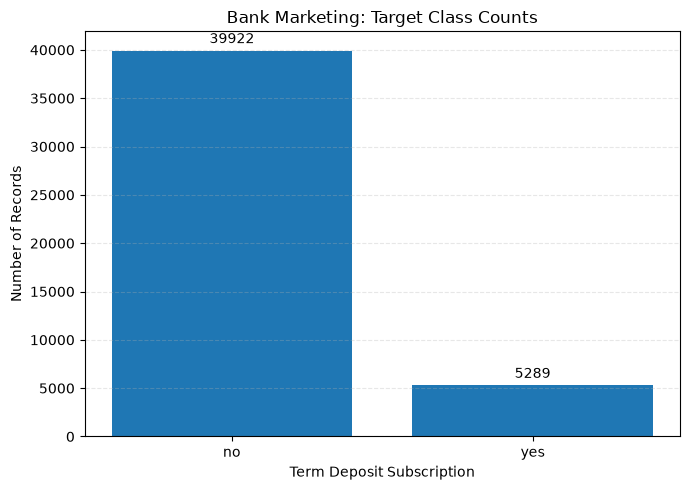


Target class counts:


,number_of_records
y,
no,39922
yes,5289



Target class percentages:


,percentage
y,
no,88.3
yes,11.7


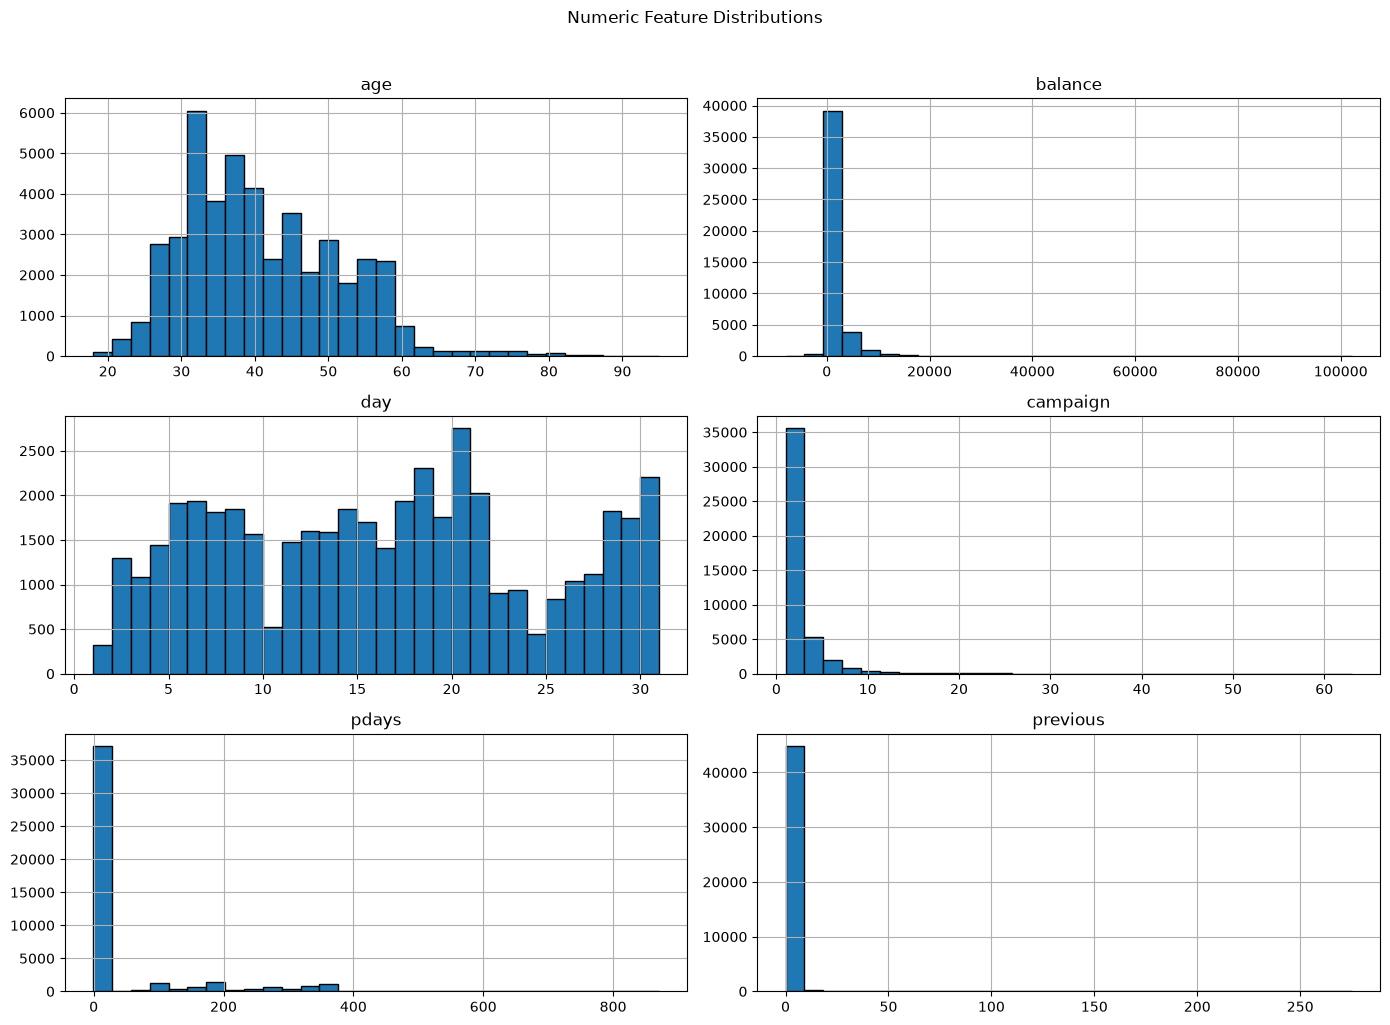

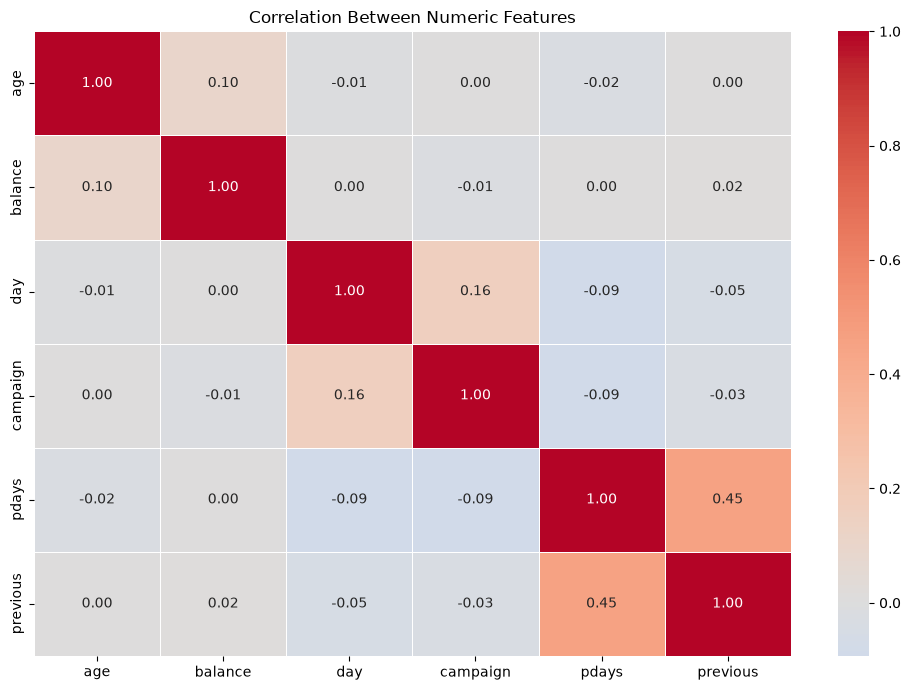

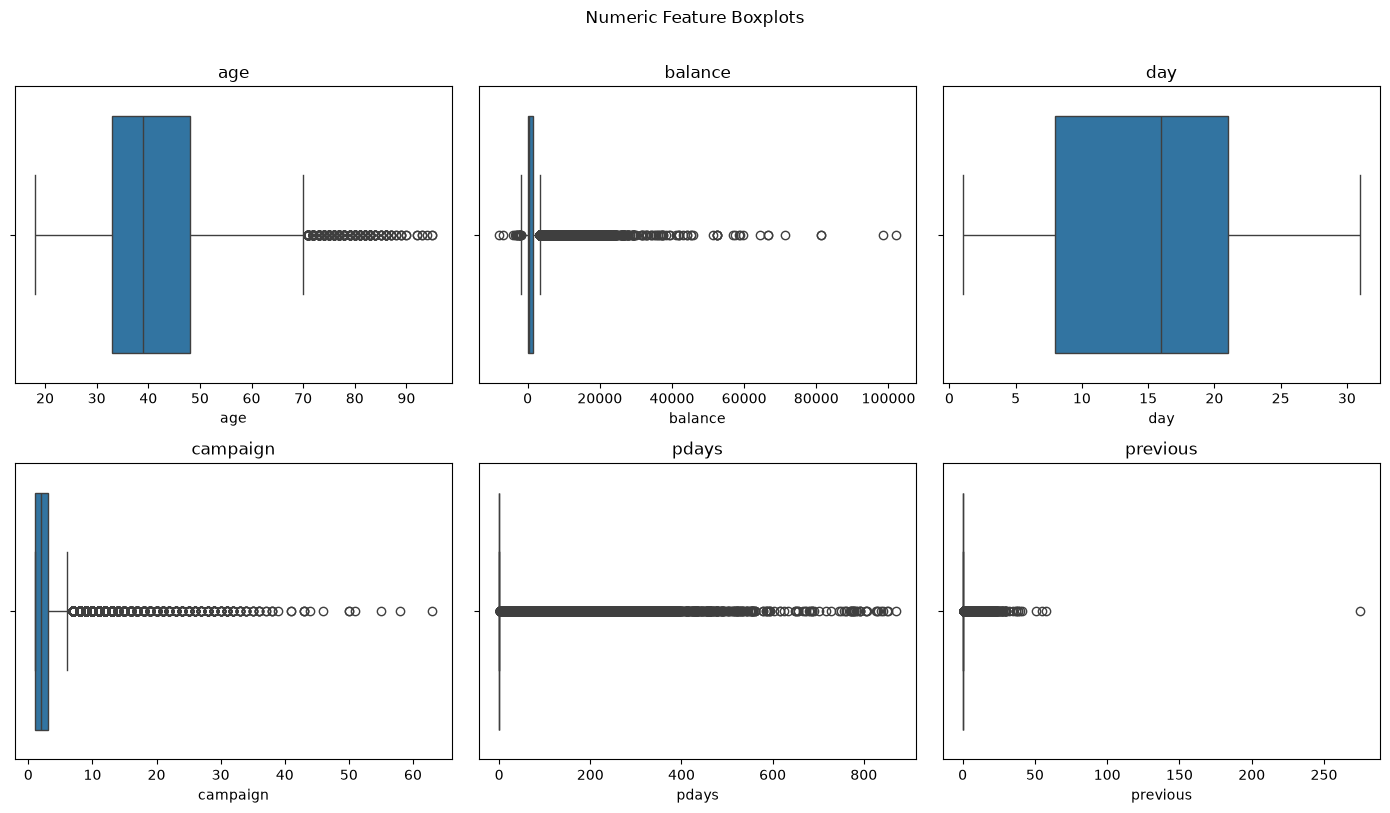


Subscription rate by job:


,count,subscription_rate_percent
feature,,
blue-collar,9732,7.27
management,9458,13.76
technician,7597,11.06
admin.,5171,12.20
services,4154,8.88
retired,2264,22.79
self-employed,1579,11.84
entrepreneur,1487,8.27
unemployed,1303,15.50


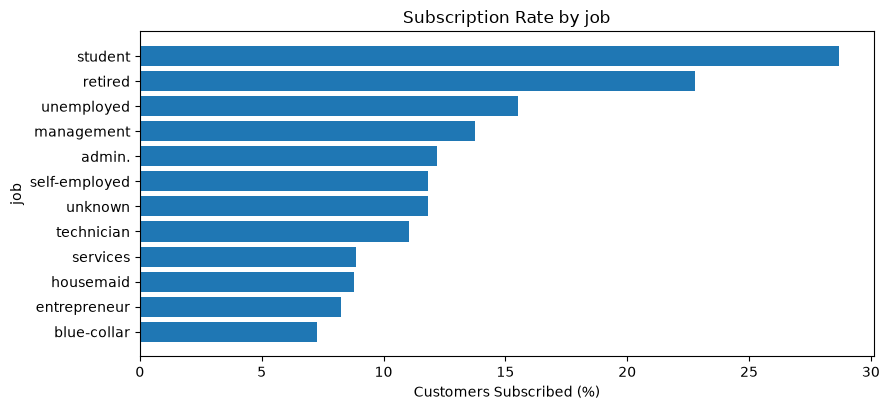


Subscription rate by marital:


,count,subscription_rate_percent
feature,,
married,27214,10.12
single,12790,14.95
divorced,5207,11.95


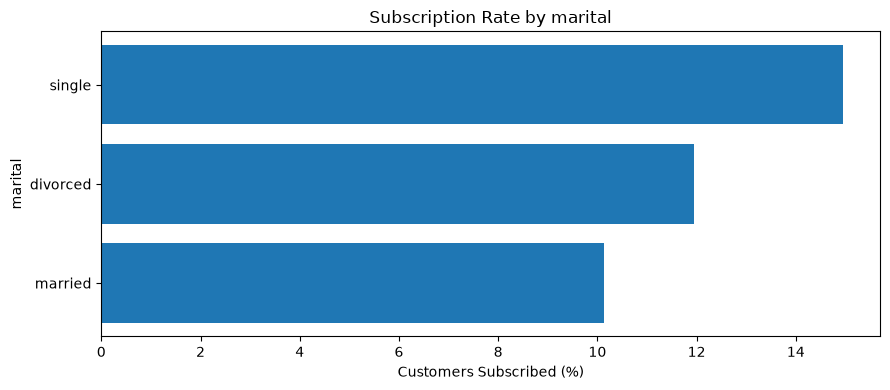


Subscription rate by education:


,count,subscription_rate_percent
feature,,
secondary,23202,10.56
tertiary,13301,15.01
primary,6851,8.63
unknown,1857,13.57


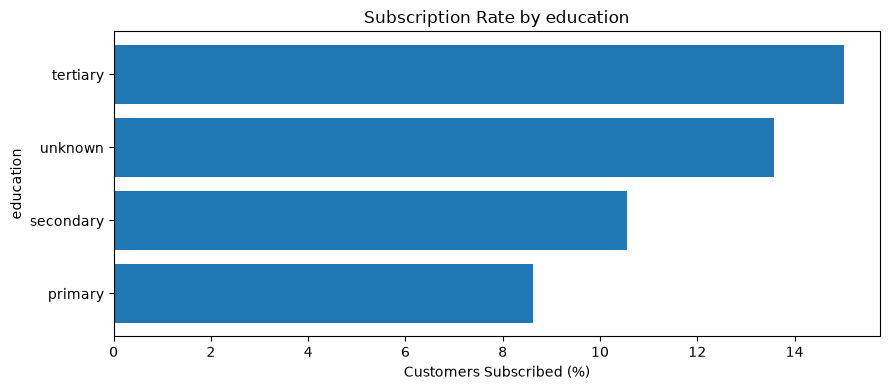


Subscription rate by default:


,count,subscription_rate_percent
feature,,
no,44396,11.80
yes,815,6.38


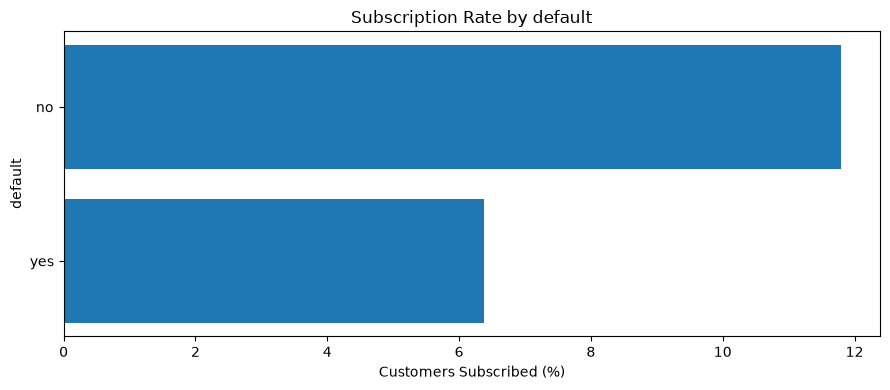


Subscription rate by housing:


,count,subscription_rate_percent
feature,,
yes,25130,7.7
no,20081,16.7


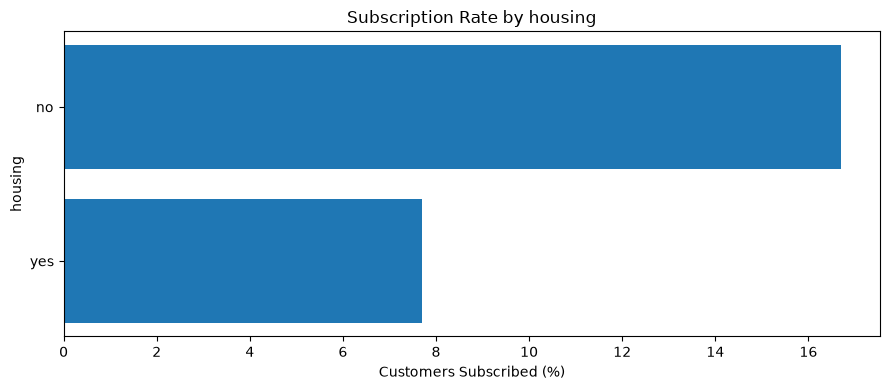


Subscription rate by loan:


,count,subscription_rate_percent
feature,,
no,37967,12.66
yes,7244,6.68


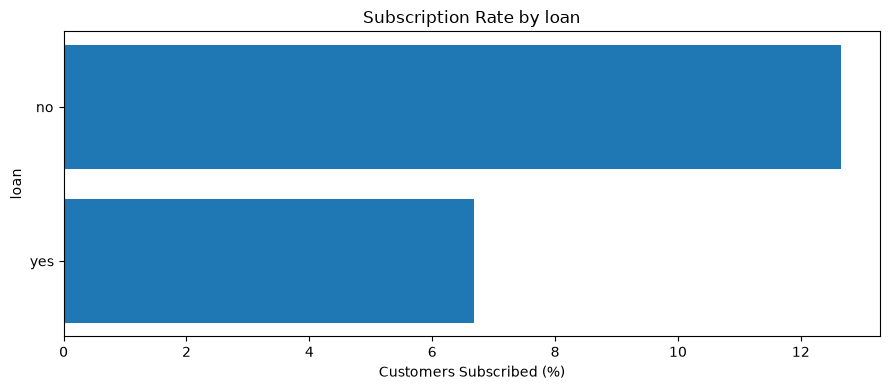


EDA completed successfully.


In [18]:

# ============================================================
# EXPLORATORY DATA ANALYSIS (EDA) GRAPHS
# Bank Marketing Dataset
# Target: Predict term deposit subscription (yes/no)
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# ------------------------------------------------------------
# 1. LOAD AND VALIDATE THE DATASET
# ------------------------------------------------------------

data_path = Path.cwd() / "bank-full.csv"

if not data_path.exists():
    print("Dataset not found in:", Path.cwd())
    print("Please select your bank-full.csv file.")

    import tkinter as tk
    from tkinter import filedialog

    root = tk.Tk()
    root.withdraw()

    selected_file = filedialog.askopenfilename(
        title="Select bank-full.csv",
        filetypes=[("CSV files", "*.csv")]
    )

    root.destroy()

    if not selected_file:
        raise FileNotFoundError(
            "No dataset selected. Please select bank-full.csv."
        )

    data_path = Path(selected_file)

# Bank Marketing bank-full.csv normally uses semicolons.
# Automatically try the common comma-separated format if needed.
df = pd.read_csv(data_path, sep=";")

if "y" not in df.columns:
    df = pd.read_csv(data_path, sep=",")

df.columns = df.columns.astype(str).str.strip()

if "y" not in df.columns:
    raise ValueError(
        "Target column 'y' was not found. "
        f"Columns detected: {df.columns.tolist()}"
    )

print("Dataset loaded successfully.")
print("File:", data_path.resolve())
print("Original dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

# ------------------------------------------------------------
# 2. CLEAN AND PREPARE THE TARGET
# ------------------------------------------------------------

# Normalize target labels and handle unexpected whitespace/case.
target = df["y"].astype("string").str.strip().str.lower()

# Keep rows with valid yes/no target values only.
valid_rows = target.isin(["yes", "no"])
df = df.loc[valid_rows].copy()
target = target.loc[valid_rows]

# Rebuild y as readable labels for EDA.
y_plot = target.reset_index(drop=True)

# Rebuild y_numeric for calculations and modelling.
y = y_plot.map({"no": 0, "yes": 1}).astype("int64")

# Remove the target and duration from the predictors.
# Duration is excluded because it is only known after the call.
X = df.drop(
    columns=["y", "duration"],
    errors="ignore"
).reset_index(drop=True)

print("\nData preparation completed.")
print("Valid records:", len(df))
print("X shape:", X.shape)
print("y shape:", y.shape)

if X.empty or y.empty:
    raise ValueError(
        "X or y is empty. Check that the selected CSV contains data."
    )

if len(X) != len(y):
    raise ValueError(
        f"X and y have different lengths: {len(X)} vs {len(y)}"
    )

# ------------------------------------------------------------
# 3. UNKNOWN VALUES IN CATEGORICAL FEATURES
# ------------------------------------------------------------

unknown_counts = {}

for column in X.select_dtypes(
    include=["object", "category", "string"]
).columns:
    unknown_counts[column] = int(
        X[column]
        .astype("string")
        .str.strip()
        .str.lower()
        .eq("unknown")
        .sum()
    )

unknown_table = (
    pd.Series(
        unknown_counts,
        name="unknown_category_count",
        dtype="int64"
    )
    .sort_values(ascending=False)
    .to_frame()
)

print("\nUnknown categorical values by feature:")
display(unknown_table)

# ------------------------------------------------------------
# 4. TARGET CLASS DISTRIBUTION
# ------------------------------------------------------------

class_counts = (
    y_plot.value_counts()
    .reindex(["no", "yes"], fill_value=0)
)

if class_counts.sum() == 0:
    raise ValueError(
        "The target contains no valid 'yes' or 'no' values. "
        f"Raw target examples: {df['y'].head(10).tolist()}"
    )

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    class_counts.index,
    class_counts.values
)

ax.set_title("Bank Marketing: Target Class Counts")
ax.set_xlabel("Term Deposit Subscription")
ax.set_ylabel("Number of Records")
ax.bar_label(bars, fmt="%.0f", padding=3)
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

print("\nTarget class counts:")
display(class_counts.to_frame(name="number_of_records"))

print("\nTarget class percentages:")
display(
    (class_counts / class_counts.sum() * 100)
    .round(2)
    .to_frame(name="percentage")
)

# ------------------------------------------------------------
# 5. NUMERIC FEATURE DISTRIBUTIONS
# ------------------------------------------------------------

num_cols_eda = X.select_dtypes(
    include=np.number
).columns.tolist()

if num_cols_eda:
    X[num_cols_eda].hist(
        figsize=(14, 10),
        bins=30,
        edgecolor="black"
    )

    plt.suptitle(
        "Numeric Feature Distributions",
        y=1.02
    )
    plt.tight_layout()
    plt.show()
else:
    print("\nNo numeric features found for histograms.")

# ------------------------------------------------------------
# 6. NUMERIC FEATURE CORRELATION HEATMAP
# ------------------------------------------------------------

if len(num_cols_eda) >= 2:
    correlation_matrix = X[num_cols_eda].corr()

    plt.figure(figsize=(10, 7))

    sns.heatmap(
        correlation_matrix,
        cmap="coolwarm",
        center=0,
        annot=True,
        fmt=".2f",
        linewidths=0.5
    )

    plt.title("Correlation Between Numeric Features")
    plt.tight_layout()
    plt.show()
else:
    print("\nNot enough numeric features for a correlation heatmap.")

# ------------------------------------------------------------
# 7. NUMERIC FEATURE BOXPLOTS
# ------------------------------------------------------------

if num_cols_eda:
    number_of_features = len(num_cols_eda)
    number_of_rows = int(np.ceil(number_of_features / 3))

    fig, axes = plt.subplots(
        number_of_rows,
        3,
        figsize=(14, 4 * number_of_rows),
        squeeze=False
    )

    axes_flat = axes.flatten()

    for index, column in enumerate(num_cols_eda):
        sns.boxplot(
            x=X[column],
            ax=axes_flat[index]
        )
        axes_flat[index].set_title(column)
        axes_flat[index].set_xlabel(column)

    # Hide unused subplot spaces.
    for index in range(number_of_features, len(axes_flat)):
        axes_flat[index].set_visible(False)

    fig.suptitle(
        "Numeric Feature Boxplots",
        y=1.01
    )
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 8. SUBSCRIPTION RATE BY CATEGORICAL FEATURE
# ------------------------------------------------------------

cat_cols_eda = X.select_dtypes(
    exclude=np.number
).columns.tolist()

# Use a numeric target aligned with X.
target_numeric = y.reset_index(drop=True)

# Plot up to six categorical features to keep the output readable.
for column in cat_cols_eda[:6]:

    rates_data = pd.DataFrame({
        "feature": (
            X[column]
            .astype("string")
            .fillna("missing")
            .astype(str)
            .reset_index(drop=True)
        ),
        "target": target_numeric
    })

    rates = (
        rates_data.groupby("feature", dropna=False)["target"]
        .agg(["count", "mean"])
        .sort_values("count", ascending=False)
        .head(15)
    )

    rates["subscription_rate_percent"] = rates["mean"] * 100

    print(f"\nSubscription rate by {column}:")
    display(
        rates[
            ["count", "subscription_rate_percent"]
        ].round(2)
    )

    # Plot the most common categories, ordered by subscription rate.
    plot_data = rates.sort_values(
        "subscription_rate_percent"
    )

    plt.figure(figsize=(9, max(4, len(plot_data) * 0.35)))

    plt.barh(
        plot_data.index.astype(str),
        plot_data["subscription_rate_percent"]
    )

    plt.title(f"Subscription Rate by {column}")
    plt.xlabel("Customers Subscribed (%)")
    plt.ylabel(column)
    plt.tight_layout()
    plt.show()

print("\nEDA completed successfully.")


## 3. Train/test split and preprocessing
All learned transformations are inside pipelines so cross-validation fits them on each training fold only. The test set remains untouched until final evaluation.

In [19]:

# Step 1: Validate and restore the dataset if necessary
if X is None or len(X) == 0:
    if X_raw is not None and len(X_raw) > 0:
        X = X_raw.copy()
        y = y_raw.squeeze().copy()
    else:
        raise ValueError(
            "The feature dataset X is empty. "
            "Please rerun the cell that loads the Bank Marketing dataset."
        )

# Step 2: Ensure X and y have matching rows
X = X.reset_index(drop=True)
y = pd.Series(y).reset_index(drop=True)

if len(X) != len(y):
    raise ValueError(
        f"X and y have different row counts: X={len(X)}, y={len(y)}."
    )

if len(X) < 2:
    raise ValueError("At least 2 rows are required for train_test_split.")

if y.isna().any():
    raise ValueError("The target y contains missing values. Clean y before splitting.")

# Step 3: Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

# Step 4: Identify numeric and categorical features
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = [
    c for c in X_train.columns if c not in numeric_features
]

# Step 5: Define preprocessing pipelines
numeric_scaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

numeric_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Step 6: Create preprocessing transformers
preprocess_lr = ColumnTransformer([
    ("num", numeric_scaled, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])

preprocess_tree = ColumnTransformer([
    ("num", numeric_tree, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])

# Step 7: Display dataset information
print("Dataset prepared successfully.")
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Target distribution:\n", y.value_counts())


Dataset prepared successfully.
Training rows: 36168
Test rows: 9043
Numeric features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Target distribution:
 y
0    39922
1     5289
Name: count, dtype: int64


## 4. Define three base models and search spaces

In [20]:
cv = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)
scoring = {"f1": "f1", "roc_auc": "roc_auc", "precision": "precision", "recall": "recall", "accuracy": "accuracy"}

models_and_spaces = {
    "Logistic Regression": (
        Pipeline([("prep", preprocess_lr),
                  ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]),
        {
            "model__C": np.logspace(-2, 2, 9),
            "model__class_weight": [None, "balanced"]
        }
    ),
    "Random Forest": (
        Pipeline([("prep", preprocess_tree),
                  ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))]),
        {
            "model__n_estimators": [150, 250, 400],
            "model__max_depth": [None, 8, 14, 22],
            "model__min_samples_leaf": [1, 2, 5, 10],
            "model__max_features": ["sqrt", 0.5],
            "model__class_weight": [None, "balanced", "balanced_subsample"]
        }
    ),
    "Histogram Gradient Boosting": (
        Pipeline([("prep", preprocess_tree),
                  ("model", HistGradientBoostingClassifier(random_state=RANDOM_STATE))]),
        {
            "model__learning_rate": [0.03, 0.05, 0.1],
            "model__max_iter": [100, 160, 240],
            "model__max_leaf_nodes": [15, 31, 63],
            "model__min_samples_leaf": [10, 20, 40],
            "model__l2_regularization": [0.0, 0.1, 1.0]
        }
    )
}


## 5. Hyperparameter optimisation
Randomized search is limited to `N_ITER` configurations per model to keep runtime manageable. Increase it if needed. All search and selection use training data only.

In [ ]:
searches = {}
best_estimators = {}
search_rows = []

for name, (pipe, params) in models_and_spaces.items():
    print("\nTuning:", name)
    search = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=params,
        n_iter=N_ITER,
        scoring=scoring,
        refit="f1",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=1,
        return_train_score=True
    )
    start = time.perf_counter()
    search.fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    searches[name] = search
    best_estimators[name] = search.best_estimator_
    search_rows.append({
        "model": name,
        "best_cv_f1": search.best_score_,
        "best_cv_roc_auc": search.cv_results_["mean_test_roc_auc"][search.best_index_],
        "fit_search_seconds": elapsed,
        "best_params": search.best_params_
    })
    print("Best CV F1:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)

tuning_results = pd.DataFrame(search_rows)
display(tuning_results)
tuning_results.to_csv("hyperparameter_search_results.csv", index=False)



Tuning: Logistic Regression


Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best CV F1: 0.3728
Best parameters: {'model__class_weight': 'balanced', 'model__C': np.float64(31.622776601683793)}

Tuning: Random Forest
Fitting 5 folds for each of 10 candidates, totalling 50 fits


## 6. Select two models and fit soft-voting ensemble
The initial ensemble is selected from the two strongest cross-validated F1 candidates. This selection is based only on training cross-validation, not test scores.

In [ ]:
ranked = sorted(best_estimators.keys(), key=lambda k: searches[k].best_score_, reverse=True)
selected_names = ranked[:2]
print("Selected for ensemble based on training CV F1:", selected_names)
voting = VotingClassifier(
    estimators=[(f"m{i+1}", clone(best_estimators[name])) for i, name in enumerate(selected_names)],
    voting="soft",
    n_jobs=-1
)
voting.fit(X_train, y_train)


Selected for ensemble based on training CV F1: ['Random Forest', 'Logistic Regression']


,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('m1', ...), ('m2', ...)]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'soft'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",-1
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[Pipeline(step...m_state=42))]), Pipeline(step...m_state=42))])]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['age','job','marital',...,'pdays','previous','poutcome']"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()


## 7. Held-out evaluation of four candidates

In [ ]:
final_models = {name: est for name, est in best_estimators.items()}
final_models["Soft Voting Ensemble"] = voting

evaluation_rows = []
predictions = {}
probabilities = {}
conf_matrices = {}

for name, estimator in final_models.items():
    start = time.perf_counter()
    pred = estimator.predict(X_test)
    elapsed = time.perf_counter() - start
    proba = estimator.predict_proba(X_test)[:, 1]
    predictions[name] = pred
    probabilities[name] = proba
    cm = confusion_matrix(y_test, pred, labels=[0,1])
    conf_matrices[name] = cm
    evaluation_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision_yes": precision_score(y_test, pred, zero_division=0),
        "recall_yes": recall_score(y_test, pred, zero_division=0),
        "f1_yes": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, proba),
        "predict_seconds": elapsed,
        "tn": int(cm[0,0]), "fp": int(cm[0,1]),
        "fn": int(cm[1,0]), "tp": int(cm[1,1])
    })

evaluation = pd.DataFrame(evaluation_rows).sort_values("f1_yes", ascending=False)
display(evaluation.round(4))
evaluation.to_csv("test_set_model_comparison.csv", index=False)


,model,accuracy,precision_yes,recall_yes,f1_yes,roc_auc,predict_seconds,tn,fp,fn,tp
1,Random Forest,0.8588,0.4215,0.5558,0.4794,0.8025,0.4595,7178,807,470,588
3,Soft Voting Ensemble,0.8422,0.3852,0.5851,0.4645,0.8000,1.0684,6997,988,439,619
0,Logistic Regression,0.7553,0.2667,0.6238,0.3736,0.7722,0.0840,6170,1815,398,660
2,Histogram Gradient Boosting,0.8956,0.6447,0.2401,0.3499,0.8054,0.2688,7845,140,804,254


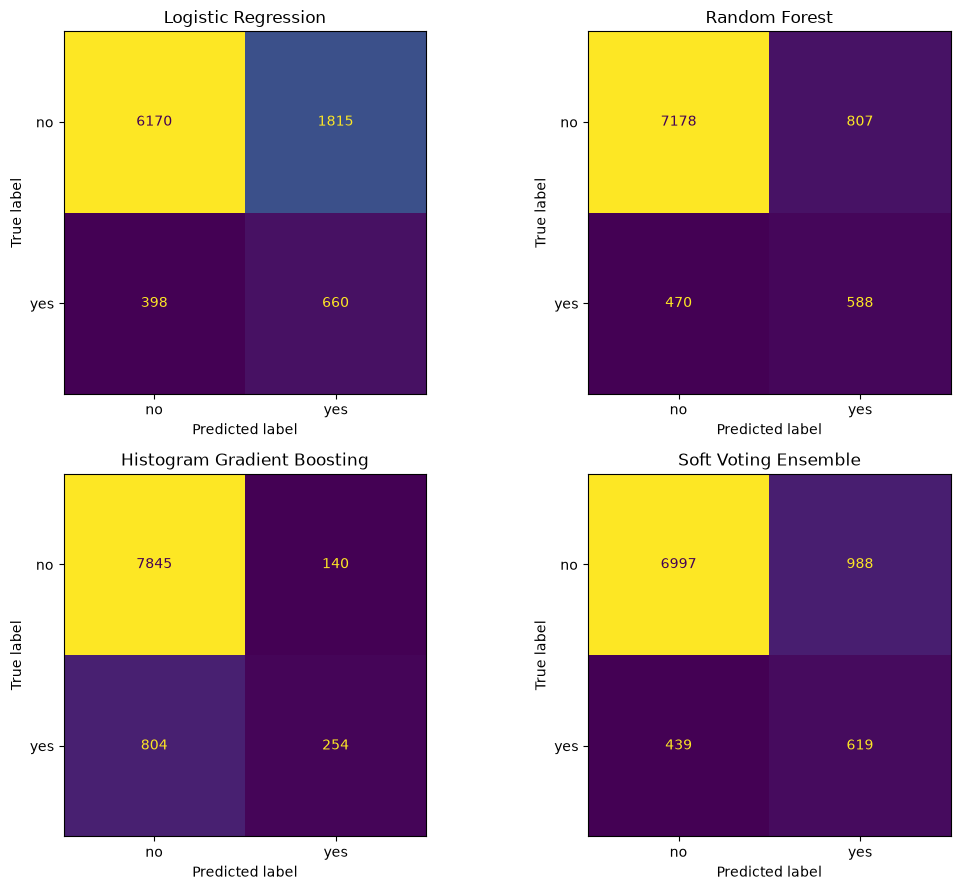

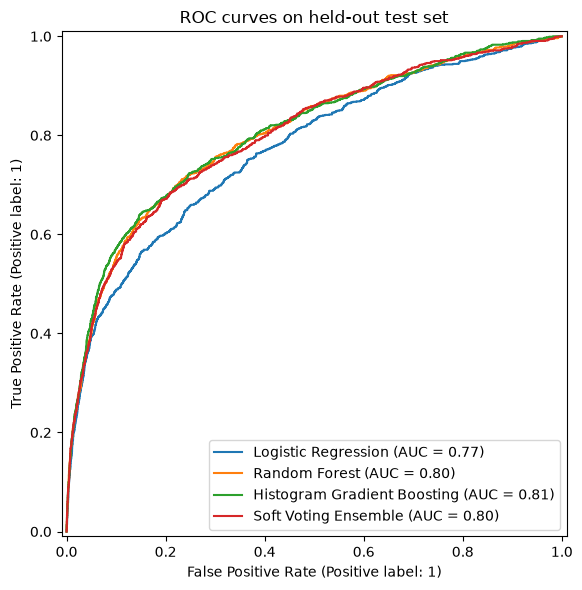


 Logistic Regression
              precision    recall  f1-score   support

          no       0.94      0.77      0.85      7985
         yes       0.27      0.62      0.37      1058

    accuracy                           0.76      9043
   macro avg       0.60      0.70      0.61      9043
weighted avg       0.86      0.76      0.79      9043


 Random Forest
              precision    recall  f1-score   support

          no       0.94      0.90      0.92      7985
         yes       0.42      0.56      0.48      1058

    accuracy                           0.86      9043
   macro avg       0.68      0.73      0.70      9043
weighted avg       0.88      0.86      0.87      9043


 Histogram Gradient Boosting
              precision    recall  f1-score   support

          no       0.91      0.98      0.94      7985
         yes       0.64      0.24      0.35      1058

    accuracy                           0.90      9043
   macro avg       0.78      0.61      0.65      9043
weight

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11,9))
for ax, (name, cm) in zip(axes.ravel(), conf_matrices.items()):
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["no","yes"])
    disp.plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(name)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7,6))
for name, estimator in final_models.items():
    RocCurveDisplay.from_predictions(y_test, probabilities[name], name=name, ax=ax)
ax.set_title("ROC curves on held-out test set")
plt.tight_layout(); plt.show()

for name in final_models:
    print("\n", name)
    print(classification_report(y_test, predictions[name], target_names=["no","yes"], zero_division=0))


## 8. Export artefacts and record findings

In [ ]:
# Save the model ranked highest on held-out F1 for inspection.
# Final deployment selection should also consider validation evidence, business costs,
# calibration, fairness, and maintainability; test-set ranking alone is not sufficient.
best_test_name = evaluation.iloc[0]["model"]
best_test_model = final_models[best_test_name]
joblib.dump(best_test_model, "bank_marketing_selected_model.joblib")
print("Highest test F1 in this run (descriptive only):", best_test_name)
print("Saved model: bank_marketing_selected_model.joblib")

print("\nDataset facts to report:")
print("Final X dimensions:", X.shape)
print("Target proportions:", y.value_counts(normalize=True).to_dict())
print("Train/test sizes:", len(X_train), len(X_test))
print("\nModel comparison table saved to test_set_model_comparison.csv")
print("Hyperparameter table saved to hyperparameter_search_results.csv")


Highest test F1 in this run (descriptive only): Random Forest
Saved model: bank_marketing_selected_model.joblib

Dataset facts to report:
Final X dimensions: (45211, 15)
Target proportions: {0: 0.8830151954170445, 1: 0.11698480458295547}
Train/test sizes: 36168 9043

Model comparison table saved to test_set_model_comparison.csv
Hyperparameter table saved to hyperparameter_search_results.csv


## 9. Report-writing checklist

After all cells run, transfer actual outputs into the report:
- Exact dataset version, row/column counts, and class proportions.
- Missing-value and duplicate counts; note that `unknown` categories are not automatically missing.
- EDA observations supported by generated charts.
- Best CV F1 and parameters for each model.
- Test-set accuracy, precision, recall, F1, ROC-AUC, confusion matrix, and runtime for all four models.
- A reasoned ensemble inclusion/exclusion decision.
- A final recommendation that discusses error costs, threshold choice, calibration, fairness, privacy, monitoring, and operational constraints.

Do not describe results as statistically significant without an appropriate statistical test or uncertainty estimate. Keep the test set out of model selection. Cite the UCI dataset as Moro et al. (2014), and cite methods in APA 7 style.
